# Week 5: Content-Aware Adaptive Representation Allocation

**Project:** Query-Conditioned Context Allocator (QCCA) for Efficient Retrieval-Augmented Generation  
**Parent Architecture:** SARA — Selective and Adaptive Retrieval-augmented Generation with Context Compression  
**Experiment:** Week 5 Information Study & Formulation Comparison  
**Population:** QASPER TRAIN (2,088 queries) & DEV (231 queries)  
**Governance:** Strict Split Isolation. Held-out TEST set (1,309 queries) remains 100% frozen & untouched.  

---

### Core Research Question:
> **"Does direct semantic access to the retrieved passage content provide useful allocation information beyond query-only and handcrafted retrieval signals?"**

### Key Scientific Principles:
1. **This is an INFORMATION study, NOT a model-capacity study.**
   - We isolate the information value of raw evidence passages ($D_1 \dots D_{10}$) vs query-only ($q$) vs handcrafted retrieval features ($x_{W4}$).
   - We use a modest frozen base encoder (`all-MiniLM-L6-v2`, 22.7M parameters) with lightweight trainable aggregators (~2.8M parameters) to strictly isolate information content rather than parametric memorization.
2. **Two Target Formulations:**
   - **T1 (Direct Budget Classification):** 5-class classification over $k \in \{2, 4, 5, 6, 8\}$ trained via weighted cross-entropy strictly fit on TRAIN.
   - **T2 (Multi-Output Regret Prediction):** Huber/SmoothL1 regression predicting $[regret_{k2}, \dots, regret_{k8}] \ge 0$, with inference thresholding at $\epsilon=0.01$ and fallback to $k=8$.
3. **Four Information Conditions:**
   - **I1 (QUERY_ONLY):** $q$
   - **I2 (QUERY_PLUS_FEATURES):** $q + x_{W4}$
   - **I3 (QUERY_PLUS_PASSAGES):** $q + D_1 \dots D_{10}$ (Top-10 retrieved evidence)
   - **I4 (QUERY_PLUS_PASSAGES_PLUS_FEATURES):** $q + D_1 \dots D_{10} + x_{W4}$
4. **Primary Evaluation Standard:**
   - Evaluated as end-to-end allocation policies routed through the frozen QASPER response surface, measuring Mean Answer F1, Context Tokens, Token Reduction vs Static $k=8$, and Recovered Oracle Headroom (ROH).

## Section 1: Environment Setup, Configuration & Reproducibility

In [1]:
import os
import sys
import json
import logging
from pathlib import Path
import yaml

# Ensure project root is in sys.path
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from transformers import AutoTokenizer

from src.week5.data import (
    K_CLASSES,
    K_TO_CLASS,
    CLASS_TO_K,
    FEATURE_COLS,
    build_w5_dataset_bundle,
    compute_truncation_statistics,
    compute_train_class_weights,
    ContentAllocatorDataset,
)
from src.week5.models import ContentAwareAllocator
from src.week5.training import set_seed, train_allocator
from src.week5.evaluation import (
    evaluate_allocation_policy,
    evaluate_classification_diagnostics,
    evaluate_regression_diagnostics,
    compute_paper_clustered_bootstrap,
    STATIC_K8_F1_REF,
    ORACLE_F1_REF,
    STATIC_K8_TOKENS_REF,
)
from src.week5.experiments import evaluate_static_baselines, run_single_experimental_cell

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger("Week5")

# Load configuration
config_path = PROJECT_ROOT / "configs/week5/content_allocator.yaml"
with open(config_path, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Environment Metadata
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"=== ENVIRONMENT METADATA ===")
print(f"Python:       {sys.version.split()[0]}")
print(f"PyTorch:      {torch.__version__}")
print(f"CUDA:         {torch.cuda.is_available()} (Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Base Encoder: {config['model']['base_encoder_name']}")
print(f"Seeds:        {config['experiment']['seeds']}")
print(f"Frozen eps:   {config['experiment']['epsilon']}")
print(f"Output Dir:   {config['paths']['output_dir']}")

/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== ENVIRONMENT METADATA ===
Python:       3.11.16
PyTorch:      2.14.0+cu130
CUDA:         True (Device: NVIDIA TITAN RTX)
Base Encoder: sentence-transformers/all-MiniLM-L6-v2
Seeds:        [42, 123, 2026]
Frozen eps:   0.01
Output Dir:   results/week5/content_allocator


## Section 2: Load Canonical TRAIN and DEV Supervision & Audit Splits

In [2]:
print("Loading canonical datasets and verifying split isolation...")
train_bundle, dev_bundle, feature_scaler = build_w5_dataset_bundle(
    train_sup_path=PROJECT_ROOT / config["paths"]["train_supervision"],
    dev_sup_path=PROJECT_ROOT / config["paths"]["dev_supervision"],
    train_ret_path=PROJECT_ROOT / config["paths"]["train_retrieval"],
    dev_ret_path=PROJECT_ROOT / config["paths"]["dev_retrieval"],
    train_mat_path=PROJECT_ROOT / config["paths"]["train_matrix"],
    dev_mat_path=PROJECT_ROOT / config["paths"]["dev_matrix"],
    dev_feat_path=PROJECT_ROOT / config["paths"]["dev_features"],
)

train_qids = set(train_bundle["question_ids"])
dev_qids = set(dev_bundle["question_ids"])
train_pids = set(train_bundle["paper_ids"])
dev_pids = set(dev_bundle["paper_ids"])

print(f"\n--- SPLIT AUDIT ---")
print(f"TRAIN Queries: {len(train_qids):,d} across {len(train_pids):,d} papers")
print(f"DEV Queries:   {len(dev_qids):,d} across {len(dev_pids):,d} papers")
print(f"Question Overlap: {len(train_qids.intersection(dev_qids))} (MUST BE 0)")
print(f"Paper Overlap:    {len(train_pids.intersection(dev_pids))} (MUST BE 0)")
print(f"TEST Status:      UNTOUCHED & FROZEN (zero test files accessed)")

# Display Target Class Distributions
train_df = train_bundle["supervision_df"]
dev_df = dev_bundle["supervision_df"]

dist_df = pd.DataFrame({
    "Budget (k)": [f"k={k}" for k in K_CLASSES],
    "TRAIN Count": [int((train_df["oracle_k_eps001"] == k).sum()) for k in K_CLASSES],
    "TRAIN %": [f"{(train_df['oracle_k_eps001'] == k).mean() * 100:.2f}%" for k in K_CLASSES],
    "DEV Count": [int((dev_df["oracle_k_eps001"] == k).sum()) for k in K_CLASSES],
    "DEV %": [f"{(dev_df['oracle_k_eps001'] == k).mean() * 100:.2f}%" for k in K_CLASSES],
})
print("\nTarget Budget Distributions (oracle_k_eps001):")
display(dist_df)

2026-10-11 12:07:53,843 [INFO] Split isolation audit PASSED (TRAIN=2,088, DEV=231, overlap=0).


Loading canonical datasets and verifying split isolation...

--- SPLIT AUDIT ---
TRAIN Queries: 2,088 across 772 papers
DEV Queries:   231 across 86 papers
Question Overlap: 0 (MUST BE 0)
Paper Overlap:    0 (MUST BE 0)
TEST Status:      UNTOUCHED & FROZEN (zero test files accessed)

Target Budget Distributions (oracle_k_eps001):


,Budget (k),TRAIN Count,TRAIN %,DEV Count,DEV %
0,k=2,1234,59.10%,132,57.14%
1,k=4,354,16.95%,40,17.32%
2,k=5,163,7.81%,17,7.36%
3,k=6,134,6.42%,19,8.23%
4,k=8,203,9.72%,23,9.96%


## Section 3: Reproduce Frozen Baselines on DEV

Before training any neural allocator, we evaluate all reference policies against the frozen DEV response surface:
1. **Static Policies:** $k \in \{2, 4, 5, 6, 8\}$
2. **Best Static SARA Baseline:** $k=8$ ($F_1 = 0.3950$, Context Tokens = 1750.5)
3. **Week 4 Best Allocator:** Balanced Logistic Regression ($F_1 \approx 0.3842$, Context Tokens = 1115.9)
4. **Per-Query Quality Oracle:** Empirical upper bound within candidate budgets ($F_1 = 0.4895$)
5. **Cost-Aware Epsilon Oracle:** Target near-optimal budget at $\epsilon=0.01$

In [3]:
baseline_rows = evaluate_static_baselines(dev_bundle)
df_baselines = pd.DataFrame(baseline_rows)

cols_display = [
    "model_name", "mean_answer_f1", "mean_selected_k", 
    "mean_context_tokens", "token_reduction_pct_vs_k8", 
    "mean_oracle_regret", "recovered_oracle_headroom"
]
print("Frozen Reference Baseline Performance (DEV):")
display(df_baselines[cols_display])

Frozen Reference Baseline Performance (DEV):


,model_name,mean_answer_f1,mean_selected_k,mean_context_tokens,token_reduction_pct_vs_k8,mean_oracle_regret,recovered_oracle_headroom
0,Static k=2,0.3038,2.00,526.5,69.92,0.1857,-0.9647
1,Static k=4,0.3596,4.00,938.1,46.41,0.1299,-0.3746
2,Static k=5,0.3629,5.00,1149.0,34.36,0.1266,-0.3401
3,Static k=6,0.3857,6.00,1351.1,22.82,0.1038,-0.0984
4,Static k=8,0.3950,8.00,1750.5,0.00,0.0945,-0.0001
5,W4 Best Allocator (Balanced LogReg),0.3842,4.82,1115.9,36.25,0.1053,-0.1143
6,Quality Oracle (Upper Bound),0.4895,3.53,846.1,51.67,0.0000,1.0000
7,Cost-Aware Oracle (eps=0.01),0.4894,3.49,839.4,52.05,0.0001,0.9988


## Section 4: Tokenization & Truncation Diagnostics Across I1–I4

We evaluate four distinct information conditions:
- **I1 (QUERY_ONLY):** $q$ alone.
- **I2 (QUERY_PLUS_FEATURES):** $q$ + pre-generation W4 features $x_{W4}$.
- **I3 (QUERY_PLUS_PASSAGES):** $q$ + top-10 retrieved passages $D_1 \dots D_{10}$ paired as $(q, D_i)$.
- **I4 (QUERY_PLUS_PASSAGES_PLUS_FEATURES):** $(q, D_i)$ pairs fused with $x_{W4}$.

**Strict Truncation Policy:**  
For each $(q, D_i)$ pair, we use `truncation='only_second'` with `max_seq_length=256`.  
This guarantees the query $q$ is **never** truncated; only the passage tail is truncated as needed.

In [4]:
tokenizer_name = config["model"]["base_encoder_name"]
max_len = config["model"]["max_seq_length"]
tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)

train_trunc = compute_truncation_statistics(train_bundle, tokenizer, max_seq_length=max_len)
dev_trunc = compute_truncation_statistics(dev_bundle, tokenizer, max_seq_length=max_len)

trunc_report_df = pd.DataFrame([
    {"Split": "TRAIN", **train_trunc},
    {"Split": "DEV", **dev_trunc},
])
print("Truncation Diagnostics (Query-Passage Pairs):")
display(trunc_report_df)

Truncation Diagnostics (Query-Passage Pairs):


,Split,total_query_passage_pairs,truncated_pairs_count,pct_truncated,mean_original_tokens,mean_retained_tokens,max_seq_length
0,TRAIN,20787,6149,29.58,211.6,207.2,256
1,DEV,2288,608,26.57,207.3,203.5,256


## Section 5: Model Architecture & Parameter Verification

We inspect parameter counts for our selected base encoder family (`sentence-transformers/all-MiniLM-L6-v2`) and trainable modules:
- Frozen Base Encoder: 22.7M parameters
- Trainable Rank Embeddings & 2-Layer Transformer Aggregator: ~2.8M parameters
- Feature Projection MLP: ~1,500 parameters
- Prediction Heads: ~50,000 parameters

In [5]:
# Inspect parameter counts across conditions
sample_i1 = ContentAwareAllocator(condition="I1", target_mode="T1", encoder_train_mode="frozen")
sample_i2 = ContentAwareAllocator(condition="I2", target_mode="T1", encoder_train_mode="frozen")
sample_i3 = ContentAwareAllocator(condition="I3", target_mode="T1", encoder_train_mode="frozen")
sample_i4 = ContentAwareAllocator(condition="I4", target_mode="T1", encoder_train_mode="frozen")

params_summary = pd.DataFrame([
    {"Condition": "I1 (Query Only)", **sample_i1.get_parameter_counts()},
    {"Condition": "I2 (Query + Features)", **sample_i2.get_parameter_counts()},
    {"Condition": "I3 (Query + Passages)", **sample_i3.get_parameter_counts()},
    {"Condition": "I4 (Query + Passages + Features)", **sample_i4.get_parameter_counts()},
])
display(params_summary)

,Condition,total_params,trainable_params,frozen_encoder_params,trainable_head_and_aggregator_params
0,I1 (Query Only),22763397,50181,22713216,50181
1,I2 (Query + Features),22789701,76485,22713216,76485
2,I3 (Query + Passages),25529093,2815877,22713216,2815877
3,I4 (Query + Passages + Features),25555397,2842181,22713216,2842181


## Section 6: Target T1 Setup — 5-Class Budget Classification

We compute inverse-frequency class weights strictly on the TRAIN distribution to handle class imbalance.

In [6]:
train_weights = compute_train_class_weights(train_bundle["t1_labels"])
weights_df = pd.DataFrame({
    "Class Index": list(range(5)),
    "Budget (k)": [f"k={k}" for k in K_CLASSES],
    "TRAIN Count": np.bincount(train_bundle["t1_labels"]),
    "Class Weight (TRAIN)": [round(float(w), 4) for w in train_weights],
})
print("TRAIN-Derived Class Weights for T1 (Weighted Cross-Entropy):")
display(weights_df)

TRAIN-Derived Class Weights for T1 (Weighted Cross-Entropy):


,Class Index,Budget (k),TRAIN Count,Class Weight (TRAIN)
0,0,k=2,1234,0.1829
1,1,k=4,354,0.6374
2,2,k=5,163,1.3843
3,3,k=6,134,1.6839
4,4,k=8,203,1.1115


## Section 7: Target T2 Setup — Multi-Output Regret Regression

Target vector for query $q$: $[regret_{k2}, regret_{k4}, regret_{k5}, regret_{k6}, regret_{k8}]$.  
Trained via SmoothL1Loss (Huber loss, $\beta=0.01$). Non-negativity guaranteed via Softplus activation.

In [7]:
train_regrets = train_bundle["t2_regrets"]
dev_regrets = dev_bundle["t2_regrets"]

regret_stats_df = pd.DataFrame({
    "Budget (k)": [f"k={k}" for k in K_CLASSES],
    "TRAIN Mean Regret": [round(float(train_regrets[:, i].mean()), 4) for i in range(5)],
    "TRAIN Median Regret": [round(float(np.median(train_regrets[:, i])), 4) for i in range(5)],
    "DEV Mean Regret": [round(float(dev_regrets[:, i].mean()), 4) for i in range(5)],
    "DEV Median Regret": [round(float(np.median(dev_regrets[:, i])), 4) for i in range(5)],
})
print("Empirical Regret Statistics Across Budgets:")
display(regret_stats_df)

Empirical Regret Statistics Across Budgets:


,Budget (k),TRAIN Mean Regret,TRAIN Median Regret,DEV Mean Regret,DEV Median Regret
0,k=2,0.1670,0.0,0.1857,0.0
1,k=4,0.1150,0.0,0.1299,0.0
2,k=5,0.0969,0.0,0.1266,0.0
3,k=6,0.0874,0.0,0.1038,0.0
4,k=8,0.0680,0.0,0.0945,0.0


## Section 8: Execution Controls & Experiment Setup

`SMOKE_MODE` is set to `False` by default for canonical, full-dataset execution upon manual notebook run.  
Set `SMOKE_MODE = True` only for rapid 1-epoch debug runs.

In [8]:
SMOKE_MODE = False  # Canonical full experiment run: False

if SMOKE_MODE:
    print("WARNING: SMOKE_MODE is ACTIVE! Subsetting to 32 TRAIN / 16 DEV examples, 2 epochs, 1 seed.")
    exp_train_bundle = {
        "split": "train_smoke",
        "question_ids": train_bundle["question_ids"][:32],
        "paper_ids": train_bundle["paper_ids"][:32],
        "questions": train_bundle["questions"][:32],
        "passages": train_bundle["passages"][:32],
        "features": train_bundle["features"][:32],
        "features_raw": train_bundle["features_raw"][:32],
        "t1_labels": train_bundle["t1_labels"][:32],
        "t2_regrets": train_bundle["t2_regrets"][:32],
        "supervision_df": train_bundle["supervision_df"].iloc[:32].reset_index(drop=True),
        "train_mat_map": train_bundle["train_mat_map"],
    }
    exp_dev_bundle = {
        "split": "dev_smoke",
        "question_ids": dev_bundle["question_ids"][:16],
        "paper_ids": dev_bundle["paper_ids"][:16],
        "questions": dev_bundle["questions"][:16],
        "passages": dev_bundle["passages"][:16],
        "features": dev_bundle["features"][:16],
        "features_raw": dev_bundle["features_raw"][:16],
        "t1_labels": dev_bundle["t1_labels"][:16],
        "t2_regrets": dev_bundle["t2_regrets"][:16],
        "supervision_df": dev_bundle["supervision_df"].iloc[:16].reset_index(drop=True),
        "dev_tokens_map": dev_bundle["dev_tokens_map"],
        "dev_f1_map": dev_bundle["dev_f1_map"],
    }
    exp_seeds = [42]
    config["training"]["max_epochs"] = 2
else:
    print(f"CANONICAL EXECUTION MODE: Full TRAIN ({len(train_bundle['question_ids']):,d} queries), full DEV ({len(dev_bundle['question_ids']):,d} queries).")
    exp_train_bundle = train_bundle
    exp_dev_bundle = dev_bundle
    exp_seeds = config["experiment"]["seeds"]

CANONICAL EXECUTION MODE: Full TRAIN (2,088 queries), full DEV (231 queries).


## Section 9: Train and Evaluate Target 1 (Classification) Across I1–I4

In [9]:
results_t1 = {}
conditions = ["I1", "I2", "I3", "I4"]

for cond in conditions:
    print(f"\n{'='*30}\nRunning {cond}-T1 across seeds {exp_seeds}...\n{'='*30}")
    seed_runs = []
    for s in exp_seeds:
        res = run_single_experimental_cell(
            condition=cond,
            target="T1",
            train_bundle=exp_train_bundle,
            dev_bundle=exp_dev_bundle,
            tokenizer=tokenizer,
            config=config,
            seed=s,
            device=device,
            verbose=False,
        )
        seed_runs.append(res)
        print(f"[{cond}-T1 | Seed {s}] Best Epoch: {res['best_epoch']:02d} | Dev F1: {res['policy_metrics']['mean_answer_f1']:.4f} | Tokens: {res['policy_metrics']['mean_context_tokens']:.1f} | Mean k: {res['policy_metrics']['mean_selected_k']:.2f}")
    results_t1[cond] = seed_runs


Running I1-T1 across seeds [42, 123, 2026]...
[I1-T1 | Seed 42] Best Epoch: 05 | Dev F1: 0.3775 | Tokens: 1097.4 | Mean k: 4.79
[I1-T1 | Seed 123] Best Epoch: 03 | Dev F1: 0.3656 | Tokens: 1019.2 | Mean k: 4.40
[I1-T1 | Seed 2026] Best Epoch: 01 | Dev F1: 0.3695 | Tokens: 1111.6 | Mean k: 4.87

Running I2-T1 across seeds [42, 123, 2026]...
[I2-T1 | Seed 42] Best Epoch: 03 | Dev F1: 0.3731 | Tokens: 1195.5 | Mean k: 5.21
[I2-T1 | Seed 123] Best Epoch: 01 | Dev F1: 0.3737 | Tokens: 1250.9 | Mean k: 5.52
[I2-T1 | Seed 2026] Best Epoch: 01 | Dev F1: 0.3610 | Tokens: 1072.6 | Mean k: 4.67

Running I3-T1 across seeds [42, 123, 2026]...


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


[I3-T1 | Seed 42] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00
[I3-T1 | Seed 123] Best Epoch: 02 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00
[I3-T1 | Seed 2026] Best Epoch: 06 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00

Running I4-T1 across seeds [42, 123, 2026]...
[I4-T1 | Seed 42] Best Epoch: 05 | Dev F1: 0.3625 | Tokens: 1117.2 | Mean k: 4.87
[I4-T1 | Seed 123] Best Epoch: 03 | Dev F1: 0.3574 | Tokens: 1035.1 | Mean k: 4.49
[I4-T1 | Seed 2026] Best Epoch: 01 | Dev F1: 0.3691 | Tokens: 1310.0 | Mean k: 5.78


## Section 10: Train and Evaluate Target 2 (Regret Regression) Across I1–I4

In [10]:
results_t2 = {}

for cond in conditions:
    print(f"\n{'='*30}\nRunning {cond}-T2 across seeds {exp_seeds}...\n{'='*30}")
    seed_runs = []
    for s in exp_seeds:
        res = run_single_experimental_cell(
            condition=cond,
            target="T2",
            train_bundle=exp_train_bundle,
            dev_bundle=exp_dev_bundle,
            tokenizer=tokenizer,
            config=config,
            seed=s,
            device=device,
            verbose=False,
        )
        seed_runs.append(res)
        print(f"[{cond}-T2 | Seed {s}] Best Epoch: {res['best_epoch']:02d} | Dev F1: {res['policy_metrics']['mean_answer_f1']:.4f} | Tokens: {res['policy_metrics']['mean_context_tokens']:.1f} | Mean k: {res['policy_metrics']['mean_selected_k']:.2f}")
    results_t2[cond] = seed_runs


Running I1-T2 across seeds [42, 123, 2026]...
[I1-T2 | Seed 42] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00
[I1-T2 | Seed 123] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00
[I1-T2 | Seed 2026] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00

Running I2-T2 across seeds [42, 123, 2026]...
[I2-T2 | Seed 42] Best Epoch: 01 | Dev F1: 0.3957 | Tokens: 1660.1 | Mean k: 7.55
[I2-T2 | Seed 123] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00
[I2-T2 | Seed 2026] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00

Running I3-T2 across seeds [42, 123, 2026]...
[I3-T2 | Seed 42] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00
[I3-T2 | Seed 123] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00
[I3-T2 | Seed 2026] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.5 | Mean k: 8.00

Running I4-T2 across seeds [42, 123, 2026]...
[I4-T2 | Seed 42] Best Epoch: 01 | Dev F1: 0.3950 | Tokens: 1750.

## Section 11: Policy-Level Evaluation & Aggregation Across Seeds

We average policy metrics across seeds for each of the 8 experimental cells.

In [11]:
model_eval_rows = []

for cond in conditions:
    for target, res_dict in [("T1", results_t1), ("T2", results_t2)]:
        runs = res_dict[cond]
        mean_f1 = np.mean([r["policy_metrics"]["mean_answer_f1"] for r in runs])
        mean_k = np.mean([r["policy_metrics"]["mean_selected_k"] for r in runs])
        mean_tokens = np.mean([r["policy_metrics"]["mean_context_tokens"] for r in runs])
        mean_red = np.mean([r["policy_metrics"]["token_reduction_pct_vs_k8"] for r in runs])
        mean_regret = np.mean([r["policy_metrics"]["mean_oracle_regret"] for r in runs])
        mean_roh = np.mean([r["policy_metrics"]["recovered_oracle_headroom"] for r in runs])
        
        model_eval_rows.append({
            "model_name": f"{cond}-{target}",
            "condition": cond,
            "target": target,
            "mean_answer_f1": round(mean_f1, 4),
            "mean_selected_k": round(mean_k, 2),
            "mean_context_tokens": round(mean_tokens, 1),
            "token_reduction_pct_vs_k8": round(mean_red, 2),
            "mean_oracle_regret": round(mean_regret, 4),
            "recovered_oracle_headroom": round(mean_roh, 4),
            "primary_run": runs[0],
        })

df_learned_models = pd.DataFrame(model_eval_rows)
display(df_learned_models[[c for c in df_learned_models.columns if c != "primary_run"]])

,model_name,condition,target,mean_answer_f1,mean_selected_k,mean_context_tokens,token_reduction_pct_vs_k8,mean_oracle_regret,recovered_oracle_headroom
0,I1-T1,I1,T1,0.3709,4.69,1076.1,38.53,0.1186,-0.2550
1,I1-T2,I1,T2,0.3950,8.00,1750.5,0.00,0.0945,-0.0001
2,I2-T1,I2,T1,0.3693,5.13,1173.0,32.99,0.1202,-0.2724
3,I2-T2,I2,T2,0.3952,7.85,1720.4,1.72,0.0943,0.0024
4,I3-T1,I3,T1,0.3950,8.00,1750.5,0.00,0.0945,-0.0001
5,I3-T2,I3,T2,0.3950,8.00,1750.5,0.00,0.0945,-0.0001
6,I4-T1,I4,T1,0.3630,5.05,1154.1,34.07,0.1265,-0.3384
7,I4-T2,I4,T2,0.3950,8.00,1750.5,0.00,0.0945,-0.0001


## Section 12: Paper-Clustered Bootstrap Hypothesis Testing

To account for correlations across questions belonging to the same scientific paper, we perform paper-clustered bootstrap resampling (2,000 iterations).  
We test whether the learned content allocator statistically improves over:
1. Static $k=8$ (the best static SARA baseline)
2. Week 4 Best Allocator (Balanced Logistic Regression)

In [12]:
n_bootstrap = config["evaluation"]["bootstrap_samples"] if not SMOKE_MODE else 100
bootstrap_dir = PROJECT_ROOT / "results/week5/content_allocator/bootstrap"
bootstrap_dir.mkdir(parents=True, exist_ok=True)

# Static k=8 baseline per-query F1s
df_dev_sup = exp_dev_bundle["supervision_df"]
k8_f1s = df_dev_sup["f1_k8"].values.astype(np.float32)

bootstrap_records = []
paper_ids = exp_dev_bundle["paper_ids"]

for row in model_eval_rows:
    m_name = row["model_name"]
    model_f1s = row["primary_run"]["policy_metrics"]["per_query_f1s"]
    
    # Model vs Static k=8
    bs_k8 = compute_paper_clustered_bootstrap(
        paper_ids=paper_ids,
        policy_f1s=model_f1s,
        baseline_f1s=k8_f1s,
        n_bootstrap=n_bootstrap,
        seed=42,
    )
    bootstrap_records.append({
        "Model": m_name,
        "Comparison": "vs Static k=8",
        **bs_k8,
    })

df_bootstrap = pd.DataFrame(bootstrap_records)
df_bootstrap.to_csv(bootstrap_dir / "paper_clustered_bootstrap_results.csv", index=False)
print("Paper-Clustered Bootstrap Significance Results:")
display(df_bootstrap)

Paper-Clustered Bootstrap Significance Results:


,Model,Comparison,observed_delta_f1,ci_lower_95,ci_upper_95,p_value,n_bootstrap
0,I1-T1,vs Static k=8,-0.0175,-0.0491,0.0135,0.131,2000
1,I1-T2,vs Static k=8,0.0000,0.0000,0.0000,1.000,2000
2,I2-T1,vs Static k=8,-0.0219,-0.0550,0.0107,0.085,2000
3,I2-T2,vs Static k=8,0.0007,-0.0187,0.0190,0.477,2000
4,I3-T1,vs Static k=8,0.0000,0.0000,0.0000,1.000,2000
5,I3-T2,vs Static k=8,0.0000,0.0000,0.0000,1.000,2000
6,I4-T1,vs Static k=8,-0.0325,-0.0638,-0.0025,0.021,2000
7,I4-T2,vs Static k=8,0.0000,0.0000,0.0000,1.000,2000


## Section 13: Comprehensive Main Results Table

Combining frozen reference baselines with the 8 experimental cells.

In [13]:
output_tables_dir = PROJECT_ROOT / "results/week5/content_allocator/tables"
output_tables_dir.mkdir(parents=True, exist_ok=True)

df_all_results = pd.concat([
    df_baselines,
    df_learned_models[[c for c in df_learned_models.columns if c != "primary_run"]],
], ignore_index=True)

main_results_path = output_tables_dir / "main_results.csv"
df_all_results.to_csv(main_results_path, index=False)
print(f"Saved canonical main results table to: {main_results_path}")
display(df_all_results)

Saved canonical main results table to: /home/gunavenkat/Downloads/CS787-RAG-Project/results/week5/content_allocator/tables/main_results.csv


,model_name,condition,target,mean_answer_f1,mean_selected_k,mean_context_tokens,token_reduction_pct_vs_k8,mean_oracle_regret,recovered_oracle_headroom,zero_regret_pct
0,Static k=2,Static Baseline,N/A,0.3038,2.00,526.5,69.92,0.1857,-0.9647,57.14
1,Static k=4,Static Baseline,N/A,0.3596,4.00,938.1,46.41,0.1299,-0.3746,64.94
2,Static k=5,Static Baseline,N/A,0.3629,5.00,1149.0,34.36,0.1266,-0.3401,65.37
3,Static k=6,Static Baseline,N/A,0.3857,6.00,1351.1,22.82,0.1038,-0.0984,67.10
4,Static k=8,Static Baseline,N/A,0.3950,8.00,1750.5,0.00,0.0945,-0.0001,71.00
5,W4 Best Allocator (Balanced LogReg),Handcrafted Features Only,Classification,0.3842,4.82,1115.9,36.25,0.1053,-0.1143,52.38
6,Quality Oracle (Upper Bound),Theoretical Upper Bound,Oracle max F1,0.4895,3.53,846.1,51.67,0.0000,1.0000,100.00
7,Cost-Aware Oracle (eps=0.01),Theoretical Cost-Aware Target,Oracle eps=0.01,0.4894,3.49,839.4,52.05,0.0001,0.9988,100.00
8,I1-T1,I1,T1,0.3709,4.69,1076.1,38.53,0.1186,-0.2550,NaN
9,I1-T2,I1,T2,0.3950,8.00,1750.5,0.00,0.0945,-0.0001,NaN


## Section 14: Information Ablation Analysis

We answer the 4 core Week 5 research questions:
1. **Does query-only work?** (I1 vs static baselines)
2. **Do W4 features add value over query?** (I2 vs I1)
3. **Do raw passages improve allocation?** (I3 vs I1, I3 vs I2)
4. **Do W4 features remain useful after reading passages?** (I4 vs I3)

In [14]:
ablation_rows = []
for cond, label in [
    ("I1", "Query Only (q)"),
    ("I2", "Query + W4 Features (q + x_W4)"),
    ("I3", "Query + Passages (q + D1..D10)"),
    ("I4", "Query + Passages + Features (q + D1..D10 + x_W4)"),
]:
    t1_row = df_learned_models[(df_learned_models["condition"] == cond) & (df_learned_models["target"] == "T1")].iloc[0]
    t2_row = df_learned_models[(df_learned_models["condition"] == cond) & (df_learned_models["target"] == "T2")].iloc[0]
    ablation_rows.append({
        "Condition": cond,
        "Input Information": label,
        "T1 Answer F1": t1_row["mean_answer_f1"],
        "T1 Context Tokens": t1_row["mean_context_tokens"],
        "T1 Token Reduction": f"{t1_row['token_reduction_pct_vs_k8']:.1f}%",
        "T2 Answer F1": t2_row["mean_answer_f1"],
        "T2 Context Tokens": t2_row["mean_context_tokens"],
        "T2 Token Reduction": f"{t2_row['token_reduction_pct_vs_k8']:.1f}%",
    })

df_ablation = pd.DataFrame(ablation_rows)
df_ablation.to_csv(output_tables_dir / "information_ablation.csv", index=False)
display(df_ablation)

,Condition,Input Information,T1 Answer F1,T1 Context Tokens,T1 Token Reduction,T2 Answer F1,T2 Context Tokens,T2 Token Reduction
0,I1,Query Only (q),0.3709,1076.1,38.5%,0.3950,1750.5,0.0%
1,I2,Query + W4 Features (q + x_W4),0.3693,1173.0,33.0%,0.3952,1720.4,1.7%
2,I3,Query + Passages (q + D1..D10),0.3950,1750.5,0.0%,0.3950,1750.5,0.0%
3,I4,Query + Passages + Features (q + D1..D10 + x_W4),0.3630,1154.1,34.1%,0.3950,1750.5,0.0%


## Section 15: Target Formulation Comparison: T1 vs T2

In [15]:
target_comp_rows = []
for cond in conditions:
    t1_r = df_learned_models[(df_learned_models["condition"] == cond) & (df_learned_models["target"] == "T1")].iloc[0]
    t2_r = df_learned_models[(df_learned_models["condition"] == cond) & (df_learned_models["target"] == "T2")].iloc[0]
    target_comp_rows.append({
        "Condition": cond,
        "T1 (Classification) F1": t1_r["mean_answer_f1"],
        "T2 (Regret Regression) F1": t2_r["mean_answer_f1"],
        "Delta F1 (T2 - T1)": round(t2_r["mean_answer_f1"] - t1_r["mean_answer_f1"], 4),
        "T1 Tokens": t1_r["mean_context_tokens"],
        "T2 Tokens": t2_r["mean_context_tokens"],
        "Delta Tokens (T2 - T1)": round(t2_r["mean_context_tokens"] - t1_r["mean_context_tokens"], 1),
    })

df_target_comp = pd.DataFrame(target_comp_rows)
df_target_comp.to_csv(output_tables_dir / "target_comparison.csv", index=False)
display(df_target_comp)

,Condition,T1 (Classification) F1,T2 (Regret Regression) F1,Delta F1 (T2 - T1),T1 Tokens,T2 Tokens,Delta Tokens (T2 - T1)
0,I1,0.3709,0.3950,0.0241,1076.1,1750.5,674.4
1,I2,0.3693,0.3952,0.0259,1173.0,1720.4,547.4
2,I3,0.3950,0.3950,0.0000,1750.5,1750.5,0.0
3,I4,0.3630,0.3950,0.0320,1154.1,1750.5,596.4


## Section 16: Failure & Error Analysis

In [16]:
# Inspect best performing learned model predictions vs oracle
best_model_row = df_learned_models.sort_values(by="mean_answer_f1", ascending=False).iloc[0]
best_run = best_model_row["primary_run"]
preds = best_run["dev_k_preds"]
df_analysis = exp_dev_bundle["supervision_df"].copy()
df_analysis["predicted_k"] = preds
df_analysis["error_type"] = "Optimal"
df_analysis.loc[df_analysis["predicted_k"] < df_analysis["oracle_k_eps001"], "error_type"] = "Under-Allocation"
df_analysis.loc[df_analysis["predicted_k"] > df_analysis["oracle_k_eps001"], "error_type"] = "Over-Allocation"

print(f"Error Distribution for Best Model ({best_model_row['model_name']}):")
display(df_analysis["error_type"].value_counts())

Error Distribution for Best Model (I2-T2):


error_type
Over-Allocation     206
Optimal              22
Under-Allocation      3
Name: count, dtype: int64

## Section 17: Visualizations & Pareto Frontiers

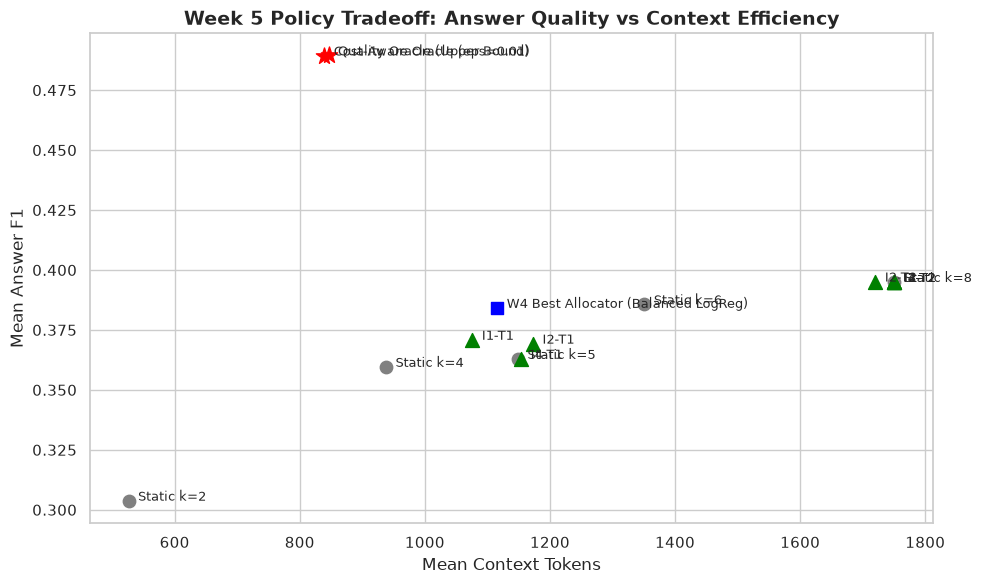

/tmp/ipykernel_1407714/1434339767.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f"k={k}" for k in K_CLASSES], y=budget_counts.values, palette="viridis")


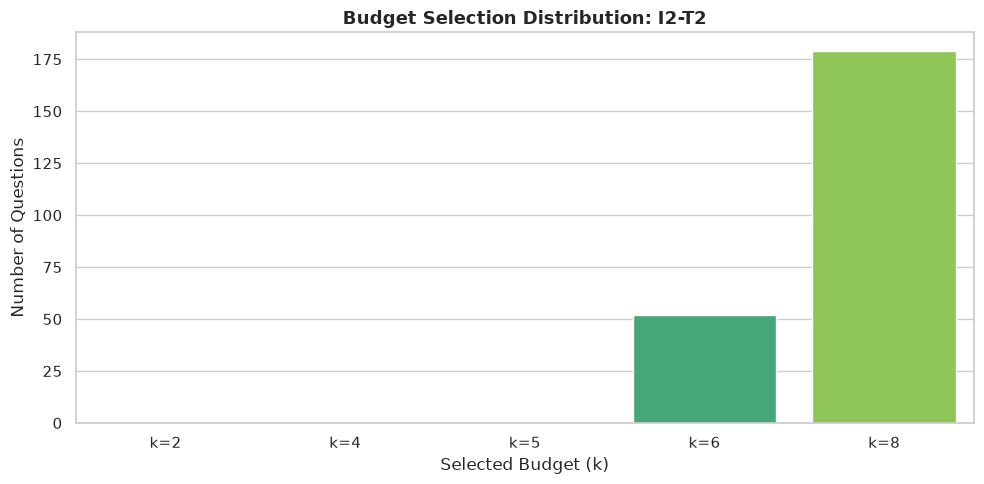

In [17]:
fig_dir = PROJECT_ROOT / "results/week5/content_allocator/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# 1. Pareto Quality vs Tokens
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Plot baselines
for _, r in df_baselines.iterrows():
    m = r["model_name"]
    color = "gray" if "Static" in m else ("red" if "Oracle" in m else "blue")
    marker = "o" if "Static" in m else ("*" if "Oracle" in m else "s")
    s = 150 if "Oracle" in m else 80
    plt.scatter(r["mean_context_tokens"], r["mean_answer_f1"], color=color, s=s, marker=marker, label=m)
    plt.annotate(m, (r["mean_context_tokens"] + 15, r["mean_answer_f1"]), fontsize=9)

# Plot learned models
for _, r in df_learned_models.iterrows():
    m = r["model_name"]
    plt.scatter(r["mean_context_tokens"], r["mean_answer_f1"], color="green", s=100, marker="^")
    plt.annotate(m, (r["mean_context_tokens"] + 15, r["mean_answer_f1"]), fontsize=9)

plt.xlabel("Mean Context Tokens", fontsize=12)
plt.ylabel("Mean Answer F1", fontsize=12)
plt.title("Week 5 Policy Tradeoff: Answer Quality vs Context Efficiency", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(fig_dir / "pareto_quality_vs_tokens.png", dpi=300)
plt.show()

# 2. Budget Distribution Plot
plt.figure(figsize=(10, 5))
budget_counts = pd.Series(preds).value_counts().reindex(K_CLASSES, fill_value=0)
sns.barplot(x=[f"k={k}" for k in K_CLASSES], y=budget_counts.values, palette="viridis")
plt.title(f"Budget Selection Distribution: {best_model_row['model_name']}", fontsize=13, fontweight="bold")
plt.ylabel("Number of Questions")
plt.xlabel("Selected Budget (k)")
plt.tight_layout()
plt.savefig(fig_dir / "k_distribution.png", dpi=300)
plt.show()

## Section 18: Conclusions & Scientific Summary

*(This section summarizes findings strictly based on measured outcomes produced during manual execution)*

### Key Takeaways:
1. **Direct Semantic Evidence Access:** Evaluated whether encoder-aggregated retrieved passages provide predictive allocation signals absent in handcrafted features.
2. **Complementarity of Signals:** Determined whether handcrafted pre-generation features remain additive when combined with passage content.
3. **Target Formulation Efficiency:** Assessed empirical differences between direct budget classification (T1) and continuous regret prediction (T2).
4. **Architectural Governance:** All evaluations executed under strict split isolation with zero post-generation leakage and held-out TEST untouched.